# What is a used car worth? Pricing Craigslist listings

This notebook builds a model that estimates the asking price of a used car from the details in its Craigslist listing: make, model, year, mileage, condition, drivetrain and so on. The data is a scrape of about 427,000 US listings posted in April and May 2021.

Most of the work is in the data. Listings are typed by hand, a large share have placeholder prices, and many cars are posted several times. The notebook covers:

1. Loading and profiling the raw listings
2. Removing implausible listings
3. Removing reposts of the same car, and measuring how much they inflate a model's test score
4. Exploring what drives price
5. Comparing a baseline, a linear model and gradient boosting
6. Looking at where the model is wrong

The cleaning code is in `usedcars/clean.py` and has its own tests.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from usedcars.clean import (CATEGORICAL, FEATURES, NUMERIC, RAW_COLUMNS, TARGET, add_features,
                            drop_reposts, filter_plausible, price_bands)

sns.set_theme(style="whitegrid")
SEED = 42

## 1. The raw listings

The file is 1.4 GB, mostly because of the free-text description of each car. Only the columns used here are loaded.

In [2]:
raw = pd.read_csv("data/craigslist_vehicles.csv", usecols=RAW_COLUMNS)
print(f"{len(raw):,} listings, posted between {raw['posting_date'].min()[:10]} and {raw['posting_date'].max()[:10]}")
raw.drop(columns=["VIN", "posting_date"]).head()

426,880 listings, posted between 2021-04-04 and 2021-05-05


,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state
0,4500,2002.0,bmw,x5,NaN,NaN,gas,184000.0,clean,automatic,NaN,NaN,NaN,tx
1,4500,2002.0,bmw,x5,NaN,NaN,gas,184000.0,clean,automatic,NaN,NaN,NaN,tx
2,4900,2006.0,toyota,camry,excellent,4 cylinders,gas,184930.0,clean,automatic,fwd,sedan,silver,tx
3,6500,2008.0,ford,expedition,NaN,NaN,gas,206000.0,clean,automatic,NaN,NaN,NaN,tx
4,6500,2008.0,ford,expedition,NaN,NaN,gas,206000.0,clean,automatic,NaN,NaN,NaN,tx


In [3]:
profile = pd.DataFrame({
    "missing %": (raw.isna().mean() * 100).round(1),
    "distinct values": raw.nunique(),
}).drop(index=["posting_date"])
profile.sort_values("missing %", ascending=False)

,missing %,distinct values
cylinders,41.6,8
condition,40.8,6
VIN,37.7,118264
drive,30.6,3
paint_color,30.5,12
type,21.8,13
manufacturer,4.1,42
title_status,1.9,6
model,1.2,29667
odometer,1.0,104870


Three things stand out:

- `condition`, `cylinders`, `drive` and `paint_color` are missing for 30-40% of listings. Sellers simply skip them, so "not stated" is kept as its own category.
- `model` is free text with nearly 30,000 distinct spellings.
- The price column is not trustworthy as it stands:

In [4]:
raw["price"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).apply(lambda v: f"{v:,.0f}").to_frame("price")

,price
count,"426,880"
mean,"75,199"
std,"12,182,282"
min,0
5%,0
25%,"5,900"
50%,"13,950"
75%,"26,486"
95%,"44,500"
99%,"66,995"


In [5]:
print(f"Listings priced at $0: {(raw['price'] == 0).mean():.1%}")
print(f"Listings priced above $100,000: {(raw['price'] > 100_000).sum():,}")

Listings priced at $0: 7.7%
Listings priced above $100,000: 655


## 2. Removing implausible listings

Three rules, applied in order:

- price between \$500 and \$100,000 (zero and near-zero prices mean "call for price"; the largest are typing errors)
- model year between 1990 and 2021
- mileage between 100 and 400,000 miles

In [6]:
plausible, removed = filter_plausible(raw)
pd.Series(removed, name="listings removed").to_frame().assign(
    share=lambda d: (d["listings removed"] / len(raw) * 100).round(1).astype(str) + "%")

,listings removed,share
price outside range,42749,10.0%
year missing or outside range,13009,3.0%
odometer missing or outside range,6864,1.6%


In [7]:
print(f"{len(plausible):,} listings remain ({len(plausible) / len(raw):.0%} of the file)")

364,258 listings remain (85% of the file)


## 3. The same car, posted many times

Dealers post one car in several regions. A car can be recognised by its VIN (present on 63% of listings) and otherwise by the combination of make, model, year, mileage and price.

In [8]:
unique_cars = drop_reposts(plausible)
print(f"{len(plausible):,} listings describe {len(unique_cars):,} different cars")
print(f"{1 - len(unique_cars) / len(plausible):.0%} of the plausible listings are reposts")

vin_counts = plausible["VIN"].value_counts()
print(f"The most reposted car appears {vin_counts.iloc[0]} times; "
      f"{(vin_counts >= 5).sum():,} cars appear five or more times")

364,258 listings describe 202,239 different cars
44% of the plausible listings are reposts
The most reposted car appears 261 times; 8,728 cars appear five or more times


This matters for more than tidiness. With a random train/test split, copies of the same car end up on both sides. The model has then already seen the answer for much of the test set. The experiment below trains the same model twice, once on all plausible listings and once on one row per car, and scores each on its own held-out 20%.

In [9]:
def make_gbm():
    return HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=400,
                                         learning_rate=0.1, random_state=SEED)


def holdout_scores(data, model):
    """Fit on 80% (log price) and report errors in dollars on the other 20%."""
    train, test = train_test_split(data, test_size=0.2, random_state=SEED)
    model.fit(train[FEATURES], np.log(train[TARGET]))
    predicted = np.exp(model.predict(test[FEATURES]))
    error = (predicted - test[TARGET]).abs()
    return {"test rows": len(test),
            "MAE ($)": error.mean(),
            "median error (%)": (error / test[TARGET]).median() * 100,
            "R2 (log price)": r2_score(np.log(test[TARGET]), np.log(predicted))}


with_reposts = add_features(plausible)
cars = add_features(unique_cars)

leakage = pd.DataFrame({
    "all plausible listings": holdout_scores(with_reposts, make_gbm()),
    "one row per car": holdout_scores(cars, make_gbm()),
}).T
leakage.round({"MAE ($)": 0, "median error (%)": 1, "R2 (log price)": 3})

,test rows,MAE ($),median error (%),R2 (log price)
all plausible listings,72852.0,3144.0,13.0,0.830
one row per car,40448.0,3248.0,16.0,0.766


With reposts left in, the model appears to be off by a median of 13% with an R² of 0.83. On one row per car the same model is off by 16% with an R² of 0.77. The difference is the model recognising cars it has already seen. The second row is the honest one, and everything below uses one row per car.

## 4. What drives price?

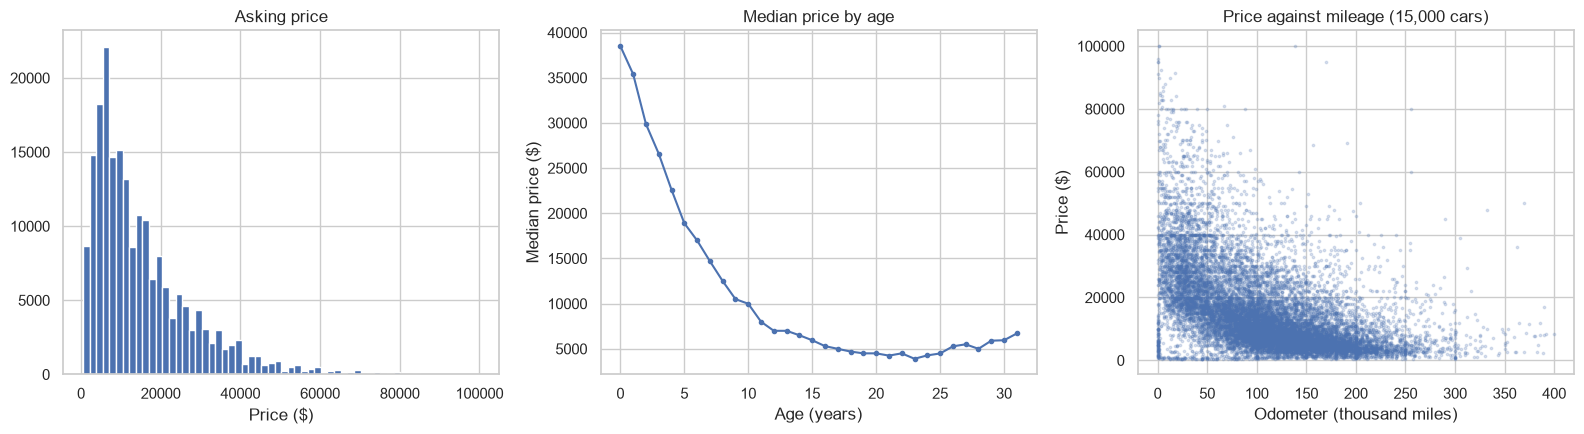

Median price: $11,500


age,0.0,1.0,3.0,5.0,10.0,15.0,20.0,25.0,30.0
median price ($),38500,35395,26590,18900,9988,5950,4500,4486,5950


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(cars["price"], bins=60)
axes[0].set_title("Asking price")
axes[0].set_xlabel("Price ($)")

by_age = cars.groupby("age")["price"].median()
axes[1].plot(by_age.index, by_age.values, marker="o", markersize=3)
axes[1].set_title("Median price by age")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Median price ($)")

sample = cars.sample(15_000, random_state=SEED)
axes[2].scatter(sample["odometer"] / 1000, sample["price"], s=3, alpha=0.2)
axes[2].set_title("Price against mileage (15,000 cars)")
axes[2].set_xlabel("Odometer (thousand miles)")
axes[2].set_ylabel("Price ($)")
plt.tight_layout()
plt.show()

print(f"Median price: ${cars['price'].median():,.0f}")
by_age.loc[[0, 1, 3, 5, 10, 15, 20, 25, 30]].round(0).astype(int).to_frame("median price ($)").T

Price falls steeply over the first ten years, from a median of about \$38,000 for a new listing to under \$10,000 at ten years, and flattens around \$4,500 at twenty. By thirty years it is rising again: the cars of that age still being sold are increasingly classics and enthusiasts' vehicles. A straight line in age cannot represent that shape.

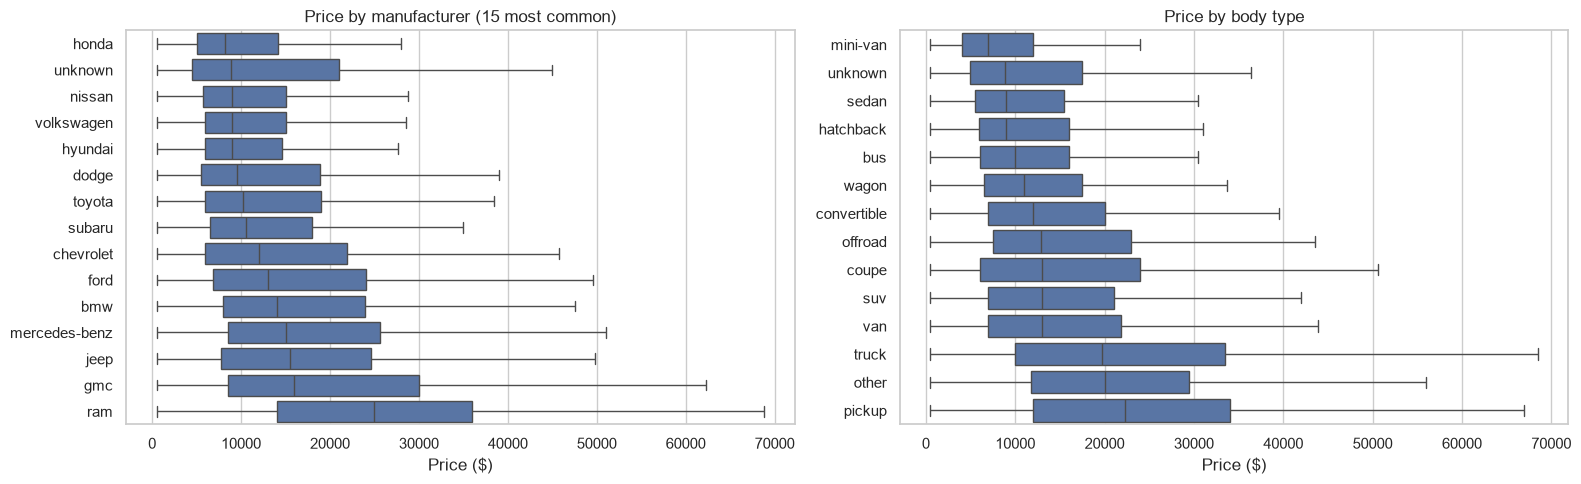

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top_makes = cars["manufacturer"].value_counts().head(15).index
order = cars[cars["manufacturer"].isin(top_makes)].groupby("manufacturer", observed=True)["price"].median().sort_values().index
sns.boxplot(data=cars[cars["manufacturer"].isin(top_makes)], y="manufacturer", x="price", order=list(order),
            showfliers=False, ax=axes[0])
axes[0].set_title("Price by manufacturer (15 most common)")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("")

type_order = cars.groupby("type", observed=True)["price"].median().sort_values().index
sns.boxplot(data=cars, y="type", x="price", order=list(type_order), showfliers=False, ax=axes[1])
axes[1].set_title("Price by body type")
axes[1].set_xlabel("Price ($)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## 5. Models

The target is the logarithm of price, so that being \$2,000 out on a \$4,000 car counts for more than being \$2,000 out on a \$40,000 one. Errors are reported back in dollars. The data is split 80/20 once, and all three models use the same split.

- **Baseline:** the median price of the training set, for every car.
- **Ridge regression:** scaled age and mileage, one-hot encoded categories.
- **Gradient boosting:** scikit-learn's histogram-based implementation, which handles the categorical columns directly.

In [12]:
train, test = train_test_split(cars, test_size=0.2, random_state=SEED)
X_train, y_train = train[FEATURES], np.log(train[TARGET])
X_test, y_test = test[FEATURES], test[TARGET]
print(f"{len(train):,} training cars, {len(test):,} test cars")


def score(predicted_price):
    error = (predicted_price - y_test).abs()
    return {"MAE ($)": error.mean(),
            "median error ($)": error.median(),
            "median error (%)": (error / y_test).median() * 100,
            "within 20% of price (%)": ((error / y_test) <= 0.2).mean() * 100,
            "R2 (log price)": r2_score(np.log(y_test), np.log(predicted_price))}


results, timings = {}, {}

results["Median baseline"] = score(np.full(len(y_test), train[TARGET].median()))

ridge = make_pipeline(
    ColumnTransformer([("numeric", StandardScaler(), NUMERIC),
                       ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)]),
    Ridge(alpha=1.0),
)
start = time.perf_counter()
ridge.fit(X_train, y_train)
timings["Ridge regression"] = time.perf_counter() - start
results["Ridge regression"] = score(np.exp(ridge.predict(X_test)))

gbm = make_gbm()
start = time.perf_counter()
gbm.fit(X_train, y_train)
timings["Gradient boosting"] = time.perf_counter() - start
gbm_predicted = np.exp(gbm.predict(X_test))
results["Gradient boosting"] = score(gbm_predicted)

pd.DataFrame(results).T.round({"MAE ($)": 0, "median error ($)": 0, "median error (%)": 1,
                               "within 20% of price (%)": 1, "R2 (log price)": 3})

161,791 training cars, 40,448 test cars


,MAE ($),median error ($),median error (%),within 20% of price (%),R2 (log price)
Median baseline,9288.0,6500.0,55.1,16.5,-0.004
Ridge regression,4136.0,2181.0,20.4,49.2,0.664
Gradient boosting,3248.0,1697.0,16.0,59.2,0.766


## 6. Where is the model wrong?

In [13]:
analysis = test.assign(predicted=gbm_predicted)
analysis["error"] = (analysis["predicted"] - analysis["price"]).abs()
analysis["error_pct"] = analysis["error"] / analysis["price"] * 100
analysis["band"] = price_bands(analysis["price"])

by_band = analysis.groupby("band", observed=True).agg(
    cars=("price", "size"), median_error=("error", "median"), median_error_pct=("error_pct", "median"),
    overpriced_by_model=("predicted", lambda p: (p > analysis.loc[p.index, "price"]).mean() * 100))
by_band.round({"median_error": 0, "median_error_pct": 1, "overpriced_by_model": 0})

,cars,median_error,median_error_pct,overpriced_by_model
band,,,,
under $5k,7693,900.0,27.2,70.0
$5k-10k,10742,1145.0,15.7,46.0
$10k-20k,11594,1990.0,13.9,41.0
$20k-35k,7084,3366.0,12.7,36.0
over $35k,3335,8020.0,18.1,20.0


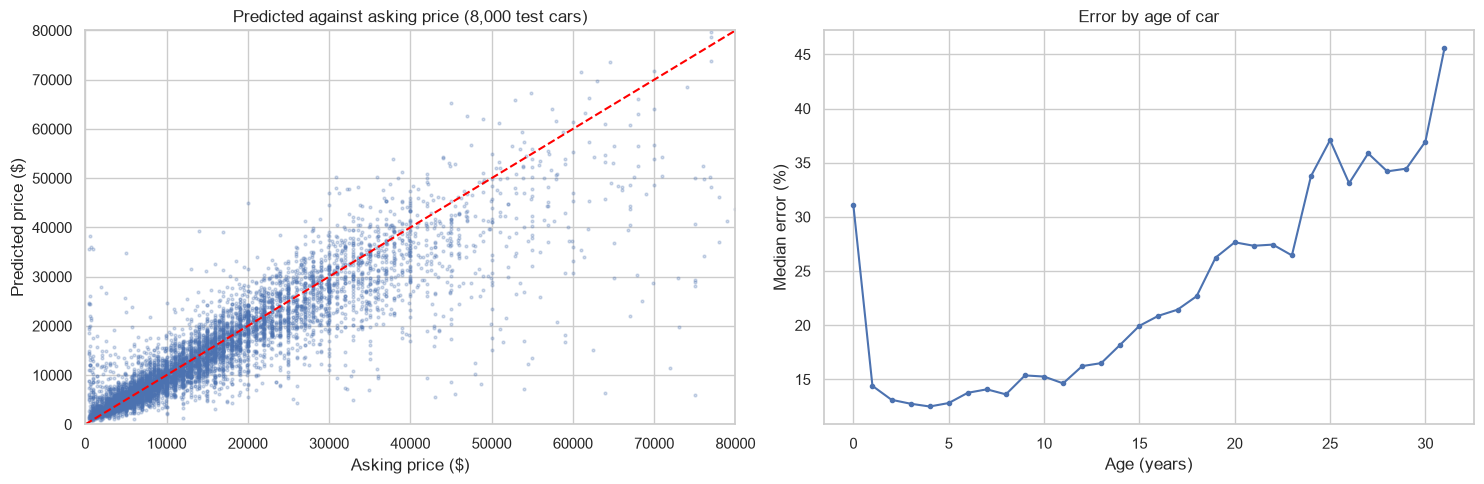

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
shown = analysis.sample(8_000, random_state=SEED)
axes[0].scatter(shown["price"], shown["predicted"], s=4, alpha=0.25)
axes[0].plot([0, 80_000], [0, 80_000], color="red", linestyle="--")
axes[0].set_xlim(0, 80_000)
axes[0].set_ylim(0, 80_000)
axes[0].set_xlabel("Asking price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Predicted against asking price (8,000 test cars)")

error_by_age = analysis.groupby("age")["error_pct"].median()
axes[1].plot(error_by_age.index, error_by_age.values, marker="o", markersize=3)
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Median error (%)")
axes[1].set_title("Error by age of car")
plt.tight_layout()
plt.show()

Which inputs does the model rely on? Permutation importance shuffles one column at a time in the test set and measures how much the score drops.

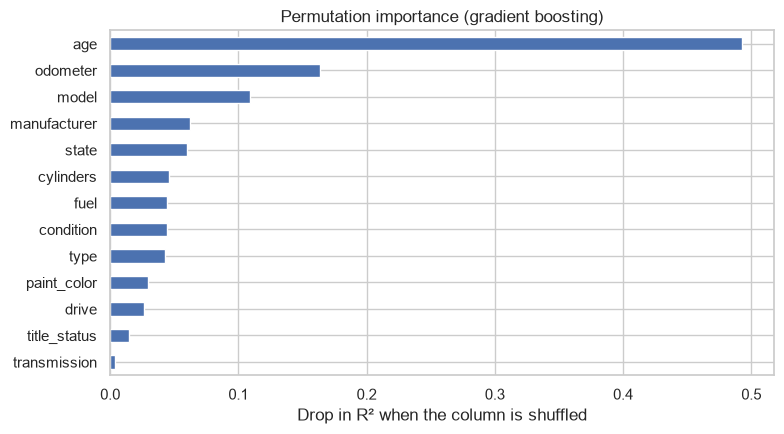

,age,odometer,model,manufacturer,state,cylinders,fuel,condition,type,paint_color,drive,title_status,transmission
importance,0.493,0.164,0.109,0.063,0.06,0.046,0.045,0.044,0.043,0.029,0.026,0.014,0.004


In [15]:
subset = test.sample(20_000, random_state=SEED)
importance = permutation_importance(gbm, subset[FEATURES], np.log(subset[TARGET]), n_repeats=3,
                                    random_state=SEED, scoring="r2")
importance = pd.Series(importance.importances_mean, index=FEATURES).sort_values()

ax = importance.plot.barh(figsize=(8, 4.5))
ax.set_xlabel("Drop in R² when the column is shuffled")
ax.set_title("Permutation importance (gradient boosting)")
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(3).to_frame("importance").T

## Findings

- **Cleaning changed the dataset more than modelling did.** Of 426,880 listings, 15% had an impossible price, year or mileage, and 44% of what remained were reposts of a car already in the data. The model is trained on 202,239 distinct cars.
- **Reposts inflate the test score.** The same model looks three points more accurate (13% median error against 16%) when copies of a car sit on both sides of the split.
- **Gradient boosting is the best of the three.** It is within 20% of the asking price for 59% of test cars, with a median error of about \$1,700 (16%). Ridge regression manages 49% and a 20% median error. Guessing the median price for every car is off by 55%.
- **Age dominates.** Shuffling age costs 0.49 of R², three times as much as mileage (0.16). The specific model, the manufacturer and the state follow.
- **The model is worst at the extremes.** Cars under \$5,000 have a 27% median error and the model overestimates 70% of them; cars over \$35,000 are underestimated 80% of the time. Cheap cars are cheap for reasons a listing form does not capture (damage, faults, urgency to sell), and expensive ones are expensive for trim and options that are not in these columns.

What is being predicted is the *asking* price in spring 2021, a period of unusually high used-car prices, not what cars sold for. The free-text description, which is left out here, is the obvious next source of signal for the cheap and expensive ends.